# PBI 1 | Explore historical SP-buy fraud data

This notebook profiles the three historical files before cleaning or training. The goal is to find data quality issues that affect joins or modelling and turn each finding into a preparation rule. All outputs use aggregate counts and charts.

Run from the project folder with Python, pandas, NumPy, Matplotlib and a Jupyter kernel. The repository keeps the three *_base.csv files in data/raw/. Set DATA_DIR in the next cell if you keep them somewhere else.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA_DIR = None  # Example: Path("/path/to/downloaded/csvs")
TABLES = ("customers", "orders", "labels")
FILENAMES = {name: f"{name}_base.csv" for name in TABLES}
ID_COLUMNS = {
    "customers": ["country_code", "customer_id"],
    "orders": ["country_code", "order_id"],
    "labels": ["country_code", "order_id", "customer_id"],
}
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
locations = [project_root / "data" / "raw"] if DATA_DIR is None else [Path(DATA_DIR)]
data_dir = next(
    (folder for folder in locations if all((folder / name).is_file() for name in FILENAMES.values())),
    None,
)
if data_dir is None:
    raise FileNotFoundError(f"Set DATA_DIR to a folder containing {', '.join(FILENAMES.values())}.")
raw = {
    name: pd.read_csv(
        data_dir / filename,
        dtype=dict.fromkeys(ID_COLUMNS[name], "string"),
        low_memory=False,
    )
    for name, filename in FILENAMES.items()
}

## 1. Structure and completeness

- **Customers:** one customer profile per customer. Country is used to validate links to orders.
- **Orders:** one order record per country and order ID. Includes date, fulfilment, payment and basket values.
- **Labels:** records the fraud outcome and carries the customer ID needed to link an order to its customer. A label of 1 means fraud and 0 means non-fraud.

Identifiers are read as strings to preserve formatting. All other types below are inferred from the CSV, so dates and mixed booleans can appear as text. A missing field does not imply a numeric value of zero.

In [2]:
structure = pd.DataFrame.from_dict(
    {
        name: {"rows": len(df), "columns": df.shape[1], "exact duplicate rows": int(df.duplicated().sum())}
        for name, df in raw.items()
    },
    orient="index",
)
display(structure)

def describe_columns(df):
    return pd.DataFrame({
        "loaded type": df.dtypes.astype(str),
        "distinct non-missing": df.nunique(),
        "missing rows": df.isna().sum(),
        "missing %": (100 * df.isna().mean()).round(3),
    })

for name, df in raw.items():
    display(describe_columns(df).rename_axis(f"{name} column"))

,rows,columns,exact duplicate rows
customers,901312,9,0
orders,949889,8,0
labels,950318,4,0


,loaded type,distinct non-missing,missing rows,missing %
customers column,,,,
country_code,string,7,0,0.000
customer_id,string,901312,0,0.000
mobile_verified,object,3,0,0.000
num_orders_last_50days,int64,433,0,0.000
num_cancelled_orders_last_50days,int64,70,0,0.000
num_refund_orders_last_50days,int64,56,0,0.000
total_payment_last_50days,float64,867702,0,0.000
num_associated_customers,int64,101,0,0.000
first_order_datetime,object,896426,712,0.079


,loaded type,distinct non-missing,missing rows,missing %
orders column,,,,
country_code,string,5,0,0.000
order_id,string,949886,0,0.000
collect_type,object,3,0,0.000
payment_method,object,20,21501,2.264
order_value,float64,514484,0,0.000
num_items_ordered,float64,160,1,0.000
refund_value,float64,4210,0,0.000
order_date,object,235,0,0.000


,loaded type,distinct non-missing,missing rows,missing %
labels column,,,,
country_code,string,7,0,0.0
order_id,string,950315,0,0.0
customer_id,string,622272,0,0.0
is_fraud,int64,2,0,0.0


The base files contain **901,312 customers, 949,889 orders and 950,318 label rows**. No exact duplicate rows were found. The main missing fields are customer first-order dates (712), payment methods (21,501) and order item counts (1). Order and label row totals are different, so coverage needs to be measured using keys.

## 2. Inconsistent formats and invalid values

Inspect the raw category values to distinguish different spellings from different categories. Check dates against the formats observed in the export and keep a separate count of values that still fail to parse.

In [3]:
customers, orders, labels = (raw[name] for name in TABLES)

def category_counts(series):
    return series.astype("string").fillna("<missing>").value_counts().rename("rows").to_frame()

country_counts = pd.concat(
    {
        name: df["country_code"].fillna("<missing>").value_counts()
        for name, df in raw.items()
    },
    axis=1,
).fillna(0).astype(int)
display(country_counts.rename_axis("country code as supplied"))
for field, df in (
    ("mobile_verified", customers), ("collect_type", orders), ("payment_method", orders)
):
    display(category_counts(df[field]).rename_axis(field))

order_dates = orders["order_date"].astype("string").str.strip()
date_formats = {
    "YYYY/MM/DD": "%Y/%m/%d",
    "YYYY-MM-DD": "%Y-%m-%d",
    "YYYY/Mon/DD": "%Y/%b/%d",
}
date_matches = {
    name: pd.to_datetime(order_dates, format=fmt, errors="coerce")
    for name, fmt in date_formats.items()
}
parsed_order_dates = date_matches["YYYY/MM/DD"].fillna(date_matches["YYYY-MM-DD"])
parsed_order_dates = parsed_order_dates.fillna(date_matches["YYYY/Mon/DD"])
parsed_customer_dates = pd.to_datetime(
    customers["first_order_datetime"].astype("string").str.strip(),
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce",
)
display(pd.Series({
    **{name: int(values.notna().sum()) for name, values in date_matches.items()},
    "missing order dates": int(order_dates.isna().sum()),
    "non-missing order dates that failed": int((order_dates.notna() & parsed_order_dates.isna()).sum()),
    "non-missing first-order dates that failed": int(
        (customers["first_order_datetime"].notna() & parsed_customer_dates.isna()).sum()
    ),
    "earliest parsed order date": parsed_order_dates.min().date(),
    "latest parsed order date": parsed_order_dates.max().date(),
}, name="result").to_frame())

,customers,orders,labels
country code as supplied,,,
MY,339134,360569,360586
PH,289358,281211,281239
PK,151877,184822,184840
TH,72509,63727,63788
BD,48044,59560,59564
pk,225,0,0
my,165,0,121
ph,0,0,180


,rows
mobile_verified,
True,900681
False,466
yes,165


,rows
collect_type,
Delivery,937730
pickup,12074
delivery,85


,rows
payment_method,
payment on Delivery,312447
cybersource,135418
online banking,124880
credit card,114242
antfinancial gcash,102657
generic creditcard,72319
balance,25936
<missing>,21501
antfinancial bkash,17889


,result
YYYY/MM/DD,949180
YYYY-MM-DD,200
YYYY/Mon/DD,509
missing order dates,0
non-missing order dates that failed,0
non-missing first-order dates that failed,0
earliest parsed order date,2022-11-12
latest parsed order date,2023-05-11


Lowercase country variants occur in both customers and labels. Standardise country codes to uppercase before checking relationships. A boolean parser should map the observed True, False and yes values explicitly. The collection and payment fields include case differences. Normalise case and whitespace first, and confirm any aliases before combining categories that differ by more than spelling.

All 949,889 base order dates parse once the three observed formats are supported. Parsing everything as YYYY/MM/DD would lose 709 valid dates.

In [4]:
CUSTOMER_NUMERIC = [
    "num_orders_last_50days", "num_cancelled_orders_last_50days",
    "num_refund_orders_last_50days", "total_payment_last_50days", "num_associated_customers",
]
ORDER_NUMERIC = ["order_value", "num_items_ordered", "refund_value"]
COUNT_FIELDS = {
    "num_orders_last_50days", "num_cancelled_orders_last_50days",
    "num_refund_orders_last_50days", "num_associated_customers", "num_items_ordered",
}

numeric = {}
quality_rows = []
for name, columns in (("customers", CUSTOMER_NUMERIC), ("orders", ORDER_NUMERIC)):
    for col in columns:
        source = raw[name][col]
        parsed = pd.to_numeric(source, errors="coerce")
        finite = parsed.where(np.isfinite(parsed))
        numeric[col] = finite
        quality_rows.append({
            "table": name,
            "field": col,
            "missing": int(source.isna().sum()),
            "non-numeric or infinite": int((source.notna() & finite.isna()).sum()),
            "negative": int(finite.lt(0).sum()),
            "non-integer count": int(finite.dropna().mod(1).ne(0).sum()) if col in COUNT_FIELDS else None,
        })
display(pd.DataFrame(quality_rows).set_index(["table", "field"]))

fraud = pd.to_numeric(labels["is_fraud"], errors="coerce")
valid_label = fraud.isin([0, 1])
verified = customers["mobile_verified"].astype("string").str.strip().str.casefold()
display(pd.Series({
    "unknown non-missing mobile verification value": int(
        (verified.notna() & ~verified.isin(["true", "false", "yes"])).sum()
    ),
    "cancelled count exceeds past order count": int(
        numeric["num_cancelled_orders_last_50days"].gt(numeric["num_orders_last_50days"]).sum()
    ),
    "refund request count exceeds past order count": int(
        numeric["num_refund_orders_last_50days"].gt(numeric["num_orders_last_50days"]).sum()
    ),
    "refund value exceeds order value": int(numeric["refund_value"].gt(numeric["order_value"]).sum()),
    "zero order value": int(numeric["order_value"].eq(0).sum()),
    "zero item count": int(numeric["num_items_ordered"].eq(0).sum()),
    "missing fraud label": int(labels["is_fraud"].isna().sum()),
    "non-missing fraud label outside 0 or 1": int((labels["is_fraud"].notna() & ~valid_label).sum()),
}, name="rows").to_frame())

missing  ...  non-integer count
table     field                                      ...                   
customers num_orders_last_50days                  0  ...                0.0
          num_cancelled_orders_last_50days        0  ...                0.0
          num_refund_orders_last_50days           0  ...                0.0
          total_payment_last_50days               0  ...                NaN
          num_associated_customers                0  ...                0.0
orders    order_value                             0  ...                NaN
          num_items_ordered                       1  ...                0.0
          refund_value                            0  ...                NaN

[8 rows x 4 columns]

,rows
unknown non-missing mobile verification value,0
cancelled count exceeds past order count,0
refund request count exceeds past order count,0
refund value exceeds order value,199687
zero order value,23
zero item count,0
missing fraud label,0
non-missing fraud label outside 0 or 1,0


Unparseable numeric fields, impossible negative values, and non-integer counts should be flagged. A refund exceeds the order value in **199,687 orders**. This is a cross-field anomaly that needs a business explanation before enforcing a limit on refunds. Keep the field in the cleaned table for analysis. A high value or a refund on its own does not establish whether an order is fraudulent.

## 3. Numeric distributions and fraud balance

Compare the median, upper percentiles and maximum to see whether a few very large values drive the range. The charts below use log(1 + value) for non-negative observations so the centre and tails remain visible. The underlying quantile table uses original units.

,min,p25,median,p75,p95,p99,max
num_orders_last_50days,0.0,5.00,14.00,29.00,70.00,117.00,2162.00
num_cancelled_orders_last_50days,0.0,0.00,0.00,0.00,1.00,3.00,259.00
num_refund_orders_last_50days,0.0,0.00,0.00,0.00,1.00,3.00,107.00
total_payment_last_50days,0.0,51.47,164.58,394.23,1057.94,1876.68,42569.35
num_associated_customers,1.0,1.00,2.00,3.00,6.00,17.00,101.00
order_value,0.0,3.21,5.51,8.51,17.64,30.98,662.88
num_items_ordered,1.0,1.00,2.00,4.00,10.00,22.00,1600.00
refund_value,0.0,0.00,0.93,2.90,8.82,16.86,518.00


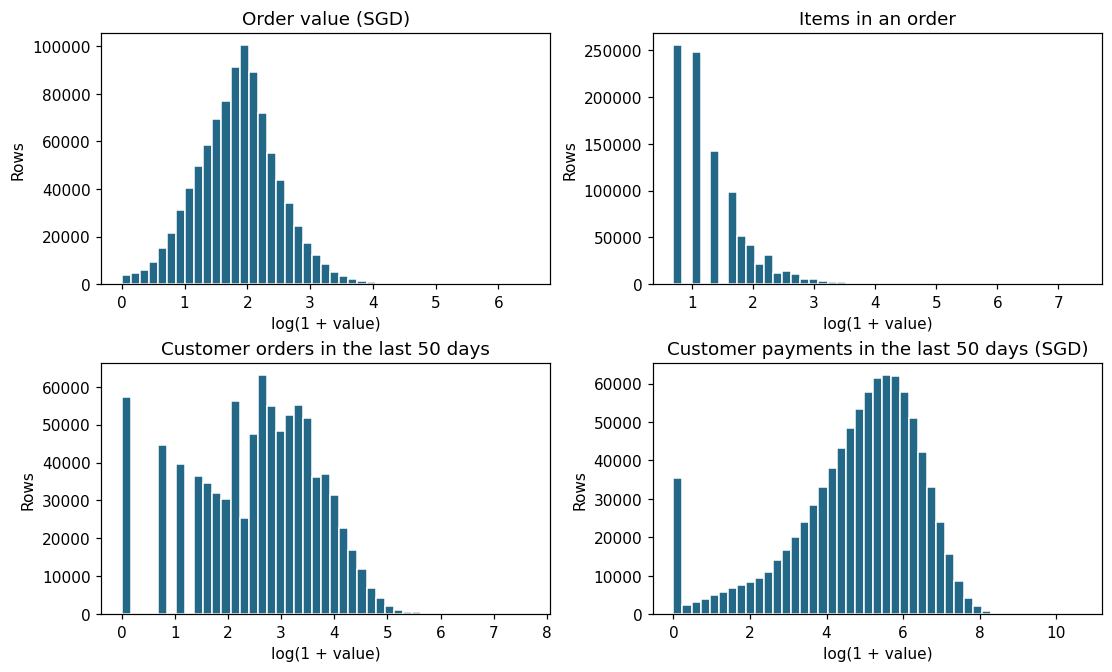

,rows,% of valid labels
is_fraud,,
Non-fraud (0),845814,89.0
Fraud (1),104504,11.0


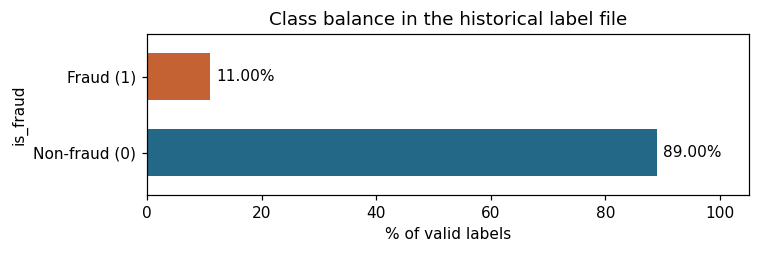

In [5]:
quantiles = pd.DataFrame(
    {name: values.quantile([0, .25, .5, .75, .95, .99, 1]) for name, values in numeric.items()}
).T
quantiles.columns = ["min", "p25", "median", "p75", "p95", "p99", "max"]
display(quantiles.round(2))

fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
for ax, field, title in zip(
    axes.flat,
    ["order_value", "num_items_ordered", "num_orders_last_50days", "total_payment_last_50days"],
    ["Order value (SGD)", "Items in an order", "Customer orders in the last 50 days",
     "Customer payments in the last 50 days (SGD)"],
):
    values = numeric[field].dropna()
    ax.hist(np.log1p(values[values.ge(0)]), bins=45, color="#236987", edgecolor="white")
    ax.set(title=title, xlabel="log(1 + value)", ylabel="Rows")
plt.show()

class_counts = fraud[valid_label].value_counts().reindex([0, 1], fill_value=0)
class_table = class_counts.rename(index={0: "Non-fraud (0)", 1: "Fraud (1)"}).rename("rows").to_frame()
class_table["% of valid labels"] = (100 * class_table["rows"] / class_table["rows"].sum()).round(2)
display(class_table)
ax = class_table["% of valid labels"].plot.barh(
    figsize=(7, 2.4), color=["#236987", "#c46233"], legend=False, width=0.62
)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.set(xlim=(0, 105), xlabel="% of valid labels", title="Class balance in the historical label file")
plt.tight_layout()
plt.show()

Most baskets are small (median 2 items) but the maximum is 1,600. The maximum order value is about SGD 662.88, compared with a median of about SGD 5.51. Keep plausible extremes and consider log transforms for skewed predictors. Investigate unusual values before deleting or capping them.

There are **104,504 fraud labels (11.00%)** and **845,814 non-fraud labels (89.00%)** in the label file. These percentages describe label rows, including any that do not match a supplied order. Missing labels should remain unlabelled. Model evaluation should report metrics such as precision and recall because the classes are imbalanced.

## 4. Candidate keys and join coverage

The order table has no customer ID. Use the label table as the bridge. First match orders to labels on country code and order ID. Then match the label's customer ID to customers using country code and customer ID. Check raw and normalised coverage to measure the effect of inconsistent country casing.

For the audits, empty IDs or malformed country codes cannot match. Distinct key sets make missing links visible without multiplying rows. The duplicate key audit below checks whether a later row-level join could multiply orders.

In [6]:
ORDER_KEY = ["country_code", "order_id"]
CUSTOMER_KEY = ["country_code", "customer_id"]
KEYS = {"customers": CUSTOMER_KEY, "orders": ORDER_KEY, "labels": ORDER_KEY}

def key_view(df, name, normalize):
    selected = df[ID_COLUMNS[name]].copy()
    if normalize:
        for col in selected.columns:
            selected[col] = selected[col].str.strip()
        selected["country_code"] = selected["country_code"].str.upper()
    country_ok = selected["country_code"].str.fullmatch(r"[A-Za-z]{2}", na=False)
    id_ok = selected[[col for col in selected if col.endswith("_id")]].apply(
        lambda column: column.str.strip().ne("").fillna(False)
    ).all(axis=1)
    return selected.loc[country_ok & id_ok]

def audit_keys(normalize):
    return {name: key_view(df, name, normalize) for name, df in raw.items()}

normalized = audit_keys(normalize=True)
key_profile = {}
for name, keys in normalized.items():
    key = KEYS[name]
    unique_pairs = keys[key].drop_duplicates()
    repeated_ids = unique_pairs.loc[unique_pairs.duplicated(key[1], keep=False), key[1]]
    key_profile[name] = {
        "rows with invalid required key fields": len(raw[name]) - len(keys),
        "rows sharing the composite key": int(keys.duplicated(key, keep=False).sum()),
        "IDs appearing in several countries": repeated_ids.nunique(),
    }
display(pd.DataFrame.from_dict(key_profile, orient="index"))

def match_coverage(key_tables):
    order_keys = key_tables["orders"][ORDER_KEY].drop_duplicates()
    customer_keys = key_tables["customers"][CUSTOMER_KEY].drop_duplicates()
    label_keys = key_tables["labels"][ORDER_KEY].drop_duplicates()
    order_labels = order_keys.merge(
        label_keys, on=ORDER_KEY, how="outer", indicator=True, validate="one_to_one"
    )
    matched_link_keys = key_tables["labels"].merge(
        order_keys, on=ORDER_KEY, how="inner", validate="many_to_one"
    )
    customer_matches = matched_link_keys.merge(
        customer_keys, on=CUSTOMER_KEY, how="left", indicator=True, validate="many_to_one"
    )
    return pd.Series({
        "order keys in both orders and labels": int(order_labels["_merge"].eq("both").sum()),
        "order keys without a corresponding label key": int(order_labels["_merge"].eq("left_only").sum()),
        "label keys without a corresponding order key": int(order_labels["_merge"].eq("right_only").sum()),
        "linked label rows without matching customer key": int(customer_matches["_merge"].eq("left_only").sum()),
        "linked label rows with matching customer key": int(customer_matches["_merge"].eq("both").sum()),
    })

display(pd.DataFrame({
    "raw keys": match_coverage(audit_keys(normalize=False)),
    "normalised keys": match_coverage(normalized),
}))

,rows with invalid required key fields,rows sharing the composite key,IDs appearing in several countries
customers,0,0,0
orders,0,0,3
labels,0,0,3


,raw keys,normalised keys
order keys in both orders and labels,949573,949874
order keys without a corresponding label key,316,15
label keys without a corresponding order key,745,444
linked label rows without matching customer key,449,2
linked label rows with matching customer key,949124,949872


Three order IDs occur in more than one country. The composite order key is unique within each base file and avoids cross-country matches. The base customer IDs are unique, and requiring country agreement gives a stricter customer link.

Normalising country codes raises the number of matched order and label keys from **949,573 to 949,874**. There are still **15 orders without a label**, **444 labels without an order**, and **2 matched order–label links without a matching customer**. The base files therefore have **949,872 fully linked rows** before further feature checks. Recheck these counts after cleaning and keep unmatched rows visible in the validation report.

## 5. Preparation decisions for PBI 2 and PBI 3

| Finding | Preparation decision |
|---|---|
| Mixed text and date formats | Strip spaces, uppercase the country codes, normalise category case, and parse the supported booleans and date formats explicitly. |
| Missing and invalid values | Preserve missing optional fields. Flag required identifier failures and invalid labels. Fit any imputation on training data only. |
| Duplicate or conflicting records | Keep one copy of an exact duplicate. Flag conflicting records that share a key so nothing is selected arbitrarily. |
| Unmatched rows | Use validated composite joins and report unmatched records and join row counts. Use only orders with a valid label and a matching customer for the shared model dataset. |
| Large values and refund anomalies | Keep plausible extremes. Document outliers and consider skew transforms. Preserve refunds in cleaned tables for RDS and analysis. |
| Class imbalance and potential leakage | Keep the fraud label separate from predictors. Exclude current-order refunds and IDs. The customer snapshot has no per-order timestamp for the 50-day fields, so omit those fields unless availability at review time is established. Split orders before fitting encoders, imputers or any balancing. |

The preparation validation notebook applies these decisions to the full history and a practice batch.